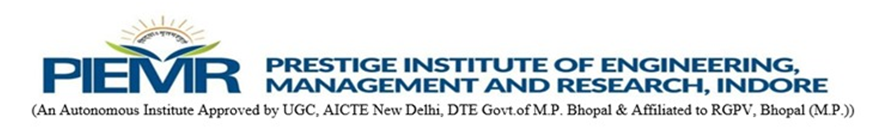

# Experiment 8 · Logistic Regression

## Aim

To estimate the probability that a student passes Mathematics using logistic regression on the UCI Student Performance dataset.

We will compare a model that uses only weekly study time with a model that also uses past failures and school absences. Both models will be evaluated on the same test students.

## Step 1 · Load the dataset and create the target

We use `student-mat.csv` from the [UCI Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student-performance). The file uses a semicolon (`;`) between columns.

| Column | Meaning |
|---|---|
| `studytime` | Weekly study-time category |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `G3` | Final Mathematics grade on a scale of 0–20 |

For this experiment, we define the target `passed` as follows.

$$
y =
\begin{cases}
1 & \text{if } G3 \geq 10 \quad \text{(Pass)}\\
0 & \text{if } G3 < 10 \quad \text{(Fail)}
\end{cases}
$$

We use `G3` to create the target and exclude it from the model inputs. Including it would give the model the information that directly determines the answer.

In [1]:
import pandas as pd

# The UCI file uses semicolons between columns
df = pd.read_csv("student-mat.csv", sep=";")

# Define Pass as a final Mathematics grade of at least 10 out of 20
df["passed"] = (df["G3"] >= 10).astype(int)

print("Dataset shape:", df.shape)
print(df[["studytime", "failures", "absences", "G3", "passed"]].head())
print("\nNumber of students in each class:")
print(df["passed"].value_counts().rename(index={0: "Fail", 1: "Pass"}))

Dataset shape: (395, 34)
   studytime  failures  absences  G3  passed
0          2         0         6   6       0
1          2         0         4   6       0
2          2         3        10  10       1
3          3         0         2  15       1
4          2         0         4  10       1

Number of students in each class:
Pass    265
Fail    130
Name: passed, dtype: int64


## Step 2 · Understand the model before training it

Logistic regression estimates the conditional probability of passing.

$$
p = P(Y=1\mid \mathbf{x}),
$$

where $\mathbf{x}$ contains the student's input features. The vertical bar means **given**, so this reads “the probability of passing given these features.” The probability of failing is $1-p$.

Suppose 8 out of 10 students pass. The probability of passing is $8/10=0.80$. The **odds** compare passes with failures, so the odds are $8/2=4$, or **4 to 1**.

$$
\text{Odds of passing}=\frac{p}{1-p}
$$

Logistic regression uses a linear equation for the **log-odds**. Taking the logarithm lets the model represent probabilities between 0 and 1 on a scale that can take any real value.

$$
z = \mathbf{w}^{\mathsf T}\mathbf{x}+b
  = \ln\left(\frac{p}{1-p}\right)
$$

During prediction, the **sigmoid** converts the score $z$ back to a probability.

$$
p=\frac{e^z}{1+e^z}=\frac{1}{1+e^{-z}}
$$

For example, if $z=\ln(4)$, the odds are $e^z=4$ and the pass probability is $4/(1+4)=0.80$.

### How the model learns

For a student with actual label $y_i$ and estimated pass probability $p_i$, the binary cross-entropy loss is

$$
\ell_i=-\left[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\right].
$$

If the student actually passed, the loss is $-\ln(p_i)$. Giving that student a pass probability of $0.80$ produces a loss of approximately $0.223$. Giving the same student a pass probability of $0.20$ produces a larger loss of approximately $1.609$.

The model fits its coefficients by minimizing the training loss with an L2 penalty on the feature weights.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

features = ["studytime", "failures", "absences"]
X = df[features]
y = df["passed"]

# Split once so both models are evaluated on the same students.
# Stratification keeps the pass/fail proportions similar in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

study_only = LogisticRegression(max_iter=1000)
study_only.fit(X_train[["studytime"]], y_train)

three_features = LogisticRegression(max_iter=1000)
three_features.fit(X_train, y_train)

# A reference model that always predicts the most common training label
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

predictions = {
    "Majority-class baseline": baseline.predict(X_test),
    "Study time only": study_only.predict(X_test[["studytime"]]),
    "Study time + failures + absences": three_features.predict(X_test)
}

results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred)
    })

print(pd.DataFrame(results).round(3).to_string(index=False))

matrix = confusion_matrix(
    y_test,
    predictions["Study time + failures + absences"],
    labels=[0, 1]
)

print("\nConfusion matrix for the three-feature model")
print(pd.DataFrame(
    matrix,
    index=["Actual Fail", "Actual Pass"],
    columns=["Predicted Fail", "Predicted Pass"]
))

                           Model  Accuracy  Balanced accuracy
         Majority-class baseline     0.667              0.500
                 Study time only     0.667              0.500
Study time + failures + absences     0.657              0.553

Confusion matrix for the three-feature model
             Predicted Fail  Predicted Pass
Actual Fail               8              25
Actual Pass               9              57


## Step 3 · Calculate one prediction manually

Consider a student with `studytime = 3`. In this dataset, category `3` represents **5–10 hours of study per week**.

For the study-time-only model, the score is

$$
z = w(3)+b,
$$

where $w$ and $b$ are the values learned from the training data. We convert this score to odds and then to a probability.

$$
\text{Odds}=e^z,\qquad
P(\text{Pass})=\frac{e^z}{1+e^z},\qquad
P(\text{Fail})=1-P(\text{Pass}).
$$

We will compare the manual probability with `predict_proba()`. The coefficient $w$ describes a change in log-odds per **study-time category step**.

In [3]:
import numpy as np

example = pd.DataFrame({"studytime": [3]})

w = study_only.coef_[0, 0]
b = study_only.intercept_[0]

# Calculate each expression from the theory
z = w * 3 + b
odds = np.exp(z)
p_pass = odds / (1 + odds)
p_fail = 1 - p_pass

print(f"Learned equation: z = {w:.4f} × studytime {b:+.4f}")
print(f"Log-odds for studytime = 3: {z:.4f}")
print(f"Odds of passing: {odds:.4f} to 1")
print(f"Probability of passing: {p_pass:.2%}")
print(f"Probability of failing: {p_fail:.2%}")
print(f"Probability from predict_proba: {study_only.predict_proba(example)[0, 1]:.2%}")
print("Predicted class:", "Pass" if study_only.predict(example)[0] == 1 else "Fail")

Learned equation: z = 0.1351 × studytime +0.4451
Log-odds for studytime = 3: 0.8503
Odds of passing: 2.3404 to 1
Probability of passing: 70.06%
Probability of failing: 29.94%
Probability from predict_proba: 70.06%
Predicted class: Pass


## Step 4 · Compare model performance

The **majority-class baseline** always predicts the most common class in the training set. It provides a reference for judging both logistic regression models.

- **Accuracy** is the fraction of test students classified correctly.
- **Balanced accuracy** is the average of the recall for Pass and the recall for Fail.
- **ROC-AUC** measures how well the predicted probabilities rank passing students above failing students across thresholds.

Use the same test set for all comparisons.

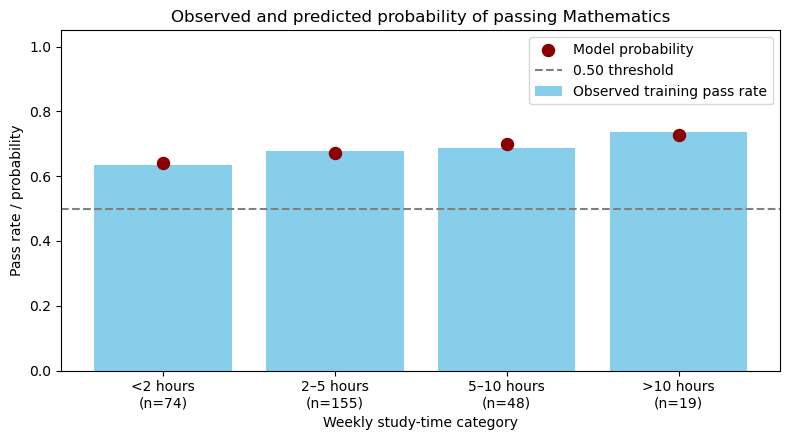

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

summary = (
    X_train[["studytime"]]
    .assign(passed=y_train)
    .groupby("studytime")["passed"]
    .agg(observed_rate="mean", n="size")
    .reindex([1, 2, 3, 4])
)

categories = pd.DataFrame({"studytime": [1, 2, 3, 4]})
predicted = study_only.predict_proba(categories)[:, 1]

study_labels = [
    f"<2 hours\n(n={n_value})" if category == 1 else
    f"{band}\n(n={n_value})"
    for category, band, n_value in zip(
        [1, 2, 3, 4],
        ["<2 hours", "2–5 hours", "5–10 hours", ">10 hours"],
        summary["n"].fillna(0).astype(int)
    )
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(summary.index, summary["observed_rate"],
       color="skyblue", label="Observed training pass rate")
ax.scatter(categories["studytime"], predicted,
           color="darkred", s=75, zorder=3, label="Model probability")
ax.axhline(0.5, color="gray", linestyle="--", label="0.50 threshold")
ax.set(
    xticks=[1, 2, 3, 4],
    xticklabels=study_labels,
    ylim=(0, 1.05),
    xlabel="Weekly study-time category",
    ylabel="Pass rate / probability",
    title="Observed and predicted probability of passing Mathematics"
)
ax.legend()
fig.tight_layout()
plt.show()

## Step 5 · Plot observed and predicted pass probabilities

For each study-time category, the **bar** shows the fraction of training students who passed. The **dot** shows the probability estimated by the study-time-only model.

The horizontal line marks the $0.50$ threshold. If all four dots are above the line, the model predicts Pass for every category at that threshold, even though the estimated probabilities differ.

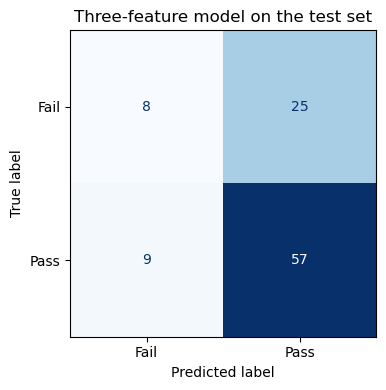

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    three_features.predict(X_test),
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)
ax.set_title("Three-feature model on the test set")
fig.tight_layout()
plt.show()

## Step 7 · Compare the ROC curves

Treat **Pass** as the positive class. The ROC curve compares the true positive rate with the false positive rate as the probability threshold changes.

- **True positive rate** is the fraction of actual passes correctly identified as Pass.
- **False positive rate** is the fraction of actual failures incorrectly identified as Pass.

Compare the two ROC-AUC scores to see which model ranks students better on this test set. The study-time-only model can produce at most four distinct scores because there are four study-time categories.

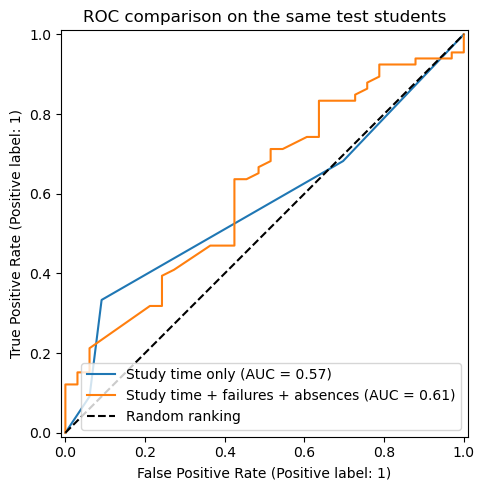

In [6]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    study_only.predict_proba(X_test[["studytime"]])[:, 1],
    name="Study time only",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    three_features.predict_proba(X_test)[:, 1],
    name="Study time + failures + absences",
    ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random ranking")
ax.set_title("ROC comparison on the same test students")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Observations

| Question | Observation |
|---|---|
| What was the estimated pass probability for `studytime = 3`? | ___ |
| Did the manual calculation agree with `predict_proba()`? | ___ |
| Which model had the higher balanced accuracy? | ___ |
| Which logistic regression model had the higher ROC-AUC? | ___ |
| How many actual failures did the three-feature model predict as Pass? | ___ |

## Result and Conclusion

The study-time-only model estimated a passing probability of **___** for a student in category 3. The manual calculation **___** the output of `predict_proba()`.

Adding past failures and absences changed the test balanced accuracy from **___** to **___** and the ROC-AUC from **___** to **___**. At the model's default decision threshold, **___** students who actually failed were predicted to pass.

## Viva Questions

1. If the probability of passing is $0.75$, what are the odds of passing?
2. Why does logistic regression express the linear score in log-odds?
3. What probability does the sigmoid return when $z=0$?
4. Why would including `G3` among the input features cause target leakage?
5. Why can two models have similar accuracy but different balanced accuracy?
6. Which cell in the confusion matrix counts actual failures predicted as Pass?

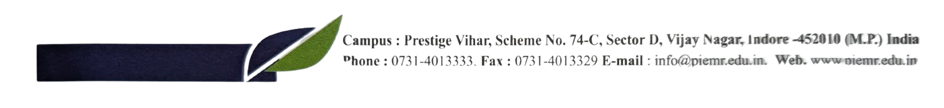